In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, Flatten

/home/vansh-talyani/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "
I0000 00:00:1793727581.979282   21318 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793727582.061995   21318 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793727584.869343   21318 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [2]:
dataset = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2
)

In [3]:
train = dataset.flow_from_directory(
    "/home/vansh-talyani/Downloads/LP IV Updated Datasets/Object Detection/caltech-101",
    target_size=(64, 64),
    batch_size=32,
    class_mode='categorical',
    subset='training'
)

test = dataset.flow_from_directory(
    "/home/vansh-talyani/Downloads/LP IV Updated Datasets/Object Detection/caltech-101",
    target_size=(64, 64),
    batch_size=32,
    class_mode='categorical',
    subset='validation'
)

Found 7356 images belonging to 102 classes.
Found 1788 images belonging to 102 classes.


In [4]:
base_model = VGG16(weights = "imagenet", include_top = False, input_shape=(64,64,3))

E0000 00:00:1793727586.417943   21318 cuda_executor.cc:1737] INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.: Error loading CUDA libraries. GPU will not be used.
W0000 00:00:1793727586.443165   21318 gpu_device.cc:2365] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


In [5]:
for layer in base_model.layers:
    layer.trainable = False

In [6]:
x = Flatten()(base_model.output)
x = Dense(64,activation='relu')(x)
output = Dense(102,activation='softmax')(x)

In [7]:
model = Model(inputs=base_model.input,outputs = output)

In [8]:
model.compile(optimizer = 'adam', loss = 'categorical_crossentropy', metrics = ['accuracy'])

In [9]:
model.fit(train,epochs=10)

Epoch 1/10


I0000 00:00:1793727595.554652   21318 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
W0000 00:00:1793727597.167625   33122 cpu_allocator_impl.cc:82] Allocation of 33554432 exceeds 10% of free system memory.
W0000 00:00:1793727597.204657   33122 cpu_allocator_impl.cc:82] Allocation of 33554432 exceeds 10% of free system memory.


  1/230 ━━━━━━━━━━━━━━━━━━━━ 7:36 2s/step - accuracy: 0.0312 - loss: 5.0004

W0000 00:00:1793727597.525679   33121 cpu_allocator_impl.cc:82] Allocation of 33554432 exceeds 10% of free system memory.
W0000 00:00:1793727597.536071   33121 cpu_allocator_impl.cc:82] Allocation of 33554432 exceeds 10% of free system memory.


  2/230 ━━━━━━━━━━━━━━━━━━━━ 1:16 335ms/step - accuracy: 0.0156 - loss: 4.8159

W0000 00:00:1793727597.860884   33119 cpu_allocator_impl.cc:82] Allocation of 33554432 exceeds 10% of free system memory.


230/230 ━━━━━━━━━━━━━━━━━━━━ 50s 211ms/step - accuracy: 0.3703 - loss: 2.9614
Epoch 2/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 47s 206ms/step - accuracy: 0.5752 - loss: 1.8443
Epoch 3/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 48s 210ms/step - accuracy: 0.6562 - loss: 1.4327
Epoch 4/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 49s 214ms/step - accuracy: 0.7031 - loss: 1.1981
Epoch 5/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 50s 216ms/step - accuracy: 0.7461 - loss: 1.0285
Epoch 6/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 52s 226ms/step - accuracy: 0.7773 - loss: 0.8952
Epoch 7/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 52s 227ms/step - accuracy: 0.8041 - loss: 0.7877
Epoch 8/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 54s 236ms/step - accuracy: 0.8272 - loss: 0.6859
Epoch 9/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 68s 294ms/step - accuracy: 0.8545 - loss: 0.6030
Epoch 10/10
230/230 ━━━━━━━━━━━━━━━━━━━━ 69s 300ms/step - accuracy: 0.8696 - loss: 0.5332


In [10]:
acc,loss  = model.evaluate(test)
print(loss)
print(acc)

56/56 ━━━━━━━━━━━━━━━━━━━━ 15s 256ms/step - accuracy: 0.6862 - loss: 1.2835
0.686241626739502
1.2835334539413452


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 574ms/step
Predicted: airplanes
Actual: airplanes


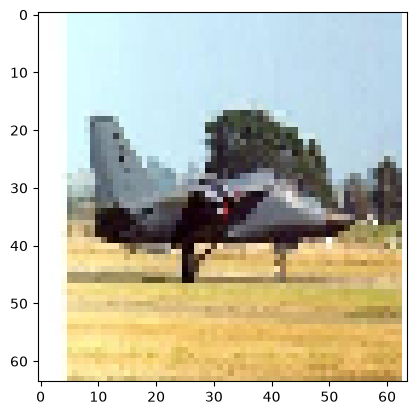

In [11]:
#TO BE DONE
labels = list(test.class_indices.keys())
x_test, y_test = test[0]
predicted_value = model.predict(x_test)

n = 5

plt.imshow(x_test[n])
print("Predicted:", labels[np.argmax(predicted_value[n])])
print("Actual:", labels[np.argmax(y_test[n])])

In [12]:
for layer in base_model.layers[-2:]:
    layer.trainable = True

In [13]:
model.compile(optimizer = 'adam', loss = 'categorical_crossentropy', metrics = ['accuracy'])

In [14]:
model.fit(train, epochs = 5, batch_size = 64)

Epoch 1/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 68s 286ms/step - accuracy: 0.5957 - loss: 1.7162
Epoch 2/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 67s 293ms/step - accuracy: 0.7384 - loss: 0.9706
Epoch 3/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 76s 331ms/step - accuracy: 0.8199 - loss: 0.6319
Epoch 4/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 84s 364ms/step - accuracy: 0.8828 - loss: 0.3977
Epoch 5/5
230/230 ━━━━━━━━━━━━━━━━━━━━ 84s 364ms/step - accuracy: 0.9171 - loss: 0.2821


In [15]:
loss, accuracy = model.evaluate(x_test, y_test)
print("Fine-tuned Accuracy:", accuracy)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 764ms/step - accuracy: 0.6562 - loss: 1.2839
Fine-tuned Accuracy: 0.65625
